Comprueba que este Jupyter puede leer los CSV de /datalake/raw y escribir Parquet en HDFS (WebHDFS).

In [1]:
import os
import pandas as pd

# Dirección de HDFS por WebHDFS (viene de las variables de entorno del contenedor)
HOST = os.environ.get('HDFS_WEBHDFS_URL', 'http://namenode:9870').replace('http://', '')
OPT = {'user': os.environ.get('HDFS_USER', 'root')}   # usuario con el que se accede a HDFS
RAW = f'webhdfs://{HOST}/datalake/raw'
CLEAN = f'webhdfs://{HOST}/datalake/clean'
print(RAW)

webhdfs://namenode:9870/datalake/raw


## 1. Lectura csv

Leemos el CSV de pedidos desde la zona raw. Cargamos todas las columnas como texto y desactivamos la conversión automática de cadenas como NA o None a valores ausentes, para poder inspeccionar primero los datos tal como vienen. Creamos df_raw para conservar el original.

In [2]:
df_raw = pd.read_csv(
    f'{RAW}/pedidos_tiempos_preparacion/02_pedidos_tiempos_preparacion.csv',
    storage_options=OPT,
    dtype=str,
    encoding='utf-8-sig',
    keep_default_na=False,
)

## 2. Primera muestra dataset

Visualizamos el dataset por primera vez a ver si podemos ir viendo datos a cambiar etc.

In [3]:
print('Filas y columnas:', df_raw.shape)
df_raw.head()

Filas y columnas: (115590, 25)


,id_pedido,fecha,hora,dia_semana,n_platos,complejidad_pedido,cola_pedidos,cocineros_disponibles,canal,prioridad_aux,...,es_hora_punta,mes,ocupacion_local,comensales,num_platos_complejos,temperatura_c,precipitacion_mm,evento_local,ingrediente_agotado,tiempo_prep_minutos
0,PED-0000001,2023-01-01,10:07:00,7,1,6.00,1,5,mesa,prioridad,...,0,1,0.05,1,0,4.2,0.0,ninguno,0,11.0
1,PED-0000002,2023-01-01,10:32:00,7,2,4.00,1,4,delivery,normal,...,0,1,0.04,2,0,4.2,0.0,ninguno,0,00:15
2,PED-0000003,2023-01-01,11:22:00,7,2,5.50,1,5,delivery,normal,...,0,1,0.15,2,1,4.2,0.0,ninguno,0,17.6
3,PED-0000004,2023-01-01,11:34:00,7,3,2.67,0,3,delivery,normal,...,0,1,0.15,3,0,4.2,0.0,ninguno,0,18.6
4,PED-0000005,2023-01-01,11:36:00,7,4,3.00,4,3,delivery,prioridad,...,0,1,0.19,2,0,4.2,0.0,ninguno,0,25.3


El archivo contiene 115.590 filas y 25 columnas. La tabla resume cuántos valores distintos hay por columna y muestra un ejemplo.

## 3. Tamaño, ejemplos y ausencias

Calculamos vacíos (incluidos los campos con solo espacios) y su porcentaje. Pasamos a NaN los vacíos y textos raros. 

También buscamos filas donde hay más platos complejos que platos en total (esto sería dato incorrecto). 

Como se leyó con keep_default_na=False, esta revisión busca explícitamente cadenas vacías.

In [4]:
# Pasar a número (los vacíos y textos raros quedan como NaN)
chk = df_raw[["n_platos", "num_platos_complejos"]].apply(pd.to_numeric, errors="coerce")

# Filas donde hay MÁS platos complejos que platos en total (imposible)
incoherentes = chk[chk["num_platos_complejos"] > chk["n_platos"]]

print(f"Filas incoherentes: {len(incoherentes):,}")
incoherentes.head(20).T

Filas incoherentes: 0


""
n_platos
num_platos_complejos


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Paleta de colores Smart Restaurant
AZUL, NARANJA, GRIS, MELOCOTON, TEXTO = "#1F3A44", "#F28C38", "#5C808E", "#FFE0C2", "#162930"
sns.set_theme(style="whitegrid", palette=[AZUL, NARANJA, GRIS, MELOCOTON], font="DejaVu Sans")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlecolor": AZUL,
                     "axes.labelcolor": TEXTO, "xtick.color": TEXTO, "ytick.color": TEXTO})

print("Filas:", f"{len(df_raw):,}", "| Columnas:", df_raw.shape[1])
print(f"Memoria: {df_raw.memory_usage(deep=True).sum() / 1e6:.1f} MB")

# Valores distintos por columna y un ejemplo (todo es texto porque leímos con dtype=str)
resumen = pd.DataFrame({"valores_distintos": df_raw.nunique(), "ejemplo": df_raw.iloc[0]})
display(resumen)

Filas: 115,590 | Columnas: 25
Memoria: 175.7 MB


,valores_distintos,ejemplo
id_pedido,114990,PED-0000001
fecha,1726,2023-01-01
hora,781,10:07:00
dia_semana,10,7
n_platos,9,1
complejidad_pedido,151,6.00
cola_pedidos,22,1
cocineros_disponibles,8,5
canal,3,mesa
prioridad_aux,3,prioridad


## 4. Revisión de columnas que deberían ser numéricas

Probamos convertir a número las columnas cuantitativas. Detectamos 342 valores lunes en dia_semana y 924 tiempos escritos como HH:MM (por ejemplo, 00:20); estos últimos requieren una conversión especial a minutos. La celda siguiente cuantifica duplicados y comprueba si los identificadores repetidos son copias idénticas.

,vacios,pct
n_platos,533,0.46
complejidad_pedido,533,0.46
tiempo_prep_minutos,521,0.45
cocineros_disponibles,509,0.44
dia_semana,505,0.44
hora,499,0.43
cola_pedidos,485,0.42
fecha,454,0.39


Columnas SIN ningún vacío: ['id_pedido', 'canal', 'prioridad_aux', 'id_local', 'estado_captura', 'es_fin_de_semana', 'es_festivo', 'franja', 'es_hora_punta', 'mes', 'ocupacion_local', 'comensales', 'num_platos_complejos', 'temperatura_c', 'precipitacion_mm', 'evento_local', 'ingrediente_agotado']


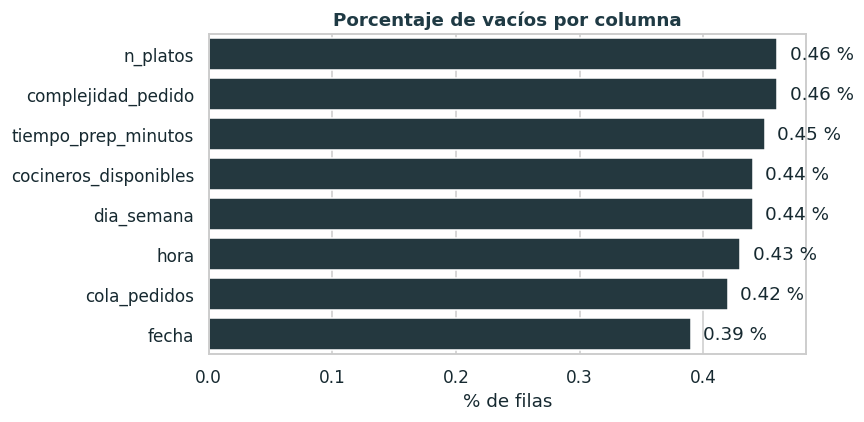

Filas con al menos un vacío: 3,463 (3.0 %)


In [6]:
# Un vacío es '' o solo espacios (con keep_default_na=False no aparecen como NaN)
vacios = df_raw.apply(lambda s: s.str.strip() == "").sum()
tabla_vacios = pd.DataFrame({"vacios": vacios, "pct": (vacios / len(df_raw) * 100).round(2)})
tabla_vacios = tabla_vacios[tabla_vacios["vacios"] > 0].sort_values("vacios", ascending=False)
display(tabla_vacios)
print("Columnas SIN ningún vacío:", [c for c in df_raw.columns if c not in tabla_vacios.index])

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=tabla_vacios["pct"], y=tabla_vacios.index, color=AZUL, ax=ax)
ax.set(title="Porcentaje de vacíos por columna", xlabel="% de filas", ylabel="")
for i, v in enumerate(tabla_vacios["pct"]):
    ax.text(v + 0.01, i, f"{v:.2f} %", va="center", color=TEXTO)
plt.tight_layout()
plt.show()

# Cuántas filas tienen al menos un vacío
filas_con_vacio = df_raw.apply(lambda s: s.str.strip() == "").any(axis=1).sum()
print(f"Filas con al menos un vacío: {filas_con_vacio:,} ({filas_con_vacio / len(df_raw) * 100:.1f} %)")

## 5. Duplicados e identificadores de pedido

Hay 600 filas duplicadas exactas y 600 repeticiones de id_pedido; no se encuentran IDs repetidos con datos distintos. Esto respalda conservar una fila por pedido al limpiar. Antes de eliminar, inspeccionamos ejemplos para confirmar que son copias completas.

In [7]:
numericas = ["dia_semana", "n_platos", "complejidad_pedido", "cola_pedidos",
             "cocineros_disponibles", "tiempo_prep_minutos", "id_local", "mes", "ocupacion_local",
             "comensales", "num_platos_complejos", "temperatura_c", "precipitacion_mm"]

for col in numericas:
    s = df_raw[col].str.strip()
    # raros = no vacíos pero que to_numeric no entiende (ej. 'lunes', '00:25')
    raros = s[(s != "") & pd.to_numeric(s, errors="coerce").isna()]
    print(f"{col:24s} {len(raros):5d} no numéricos", dict(raros.value_counts().head(5)) if len(raros) else "")

dia_semana                 342 no numéricos {'lunes': np.int64(342)}
n_platos                     0 no numéricos 
complejidad_pedido           0 no numéricos 
cola_pedidos                 0 no numéricos 
cocineros_disponibles        0 no numéricos 
tiempo_prep_minutos        924 no numéricos {'00:20': np.int64(65), '00:24': np.int64(57), '00:22': np.int64(52), '00:25': np.int64(51), '00:21': np.int64(51)}
id_local                     0 no numéricos 
mes                          0 no numéricos 
ocupacion_local              0 no numéricos 
comensales                   0 no numéricos 
num_platos_complejos         0 no numéricos 
temperatura_c                0 no numéricos 
precipitacion_mm             0 no numéricos 


## 6. Patrones de formato

Normalizamos visualmente letras y dígitos para localizar formatos distintos sin alterar los datos. Se observan fechas en formato ISO y en otro formato con el año al final, valores de dia_semana escritos como texto y tiempos de preparación con patrón de hora y minuto. Los patrones ayudan a localizar incidencias, pero no sustituyen la validación de los valores.

In [8]:
print("Filas totalmente duplicadas:", df_raw.duplicated().sum())
print("id_pedido repetidos:        ", df_raw["id_pedido"].duplicated().sum())

# ¿Son copias exactas o el mismo id con datos distintos?
rep = df_raw[df_raw["id_pedido"].duplicated(keep=False)]
distintas = rep.drop_duplicates().groupby("id_pedido").size().gt(1).sum()
print("IDs repetidos con datos DISTINTOS:", distintas)
display(rep.sort_values("id_pedido").head(4))

Filas totalmente duplicadas: 600
id_pedido repetidos:         600
IDs repetidos con datos DISTINTOS: 0


,id_pedido,fecha,hora,dia_semana,n_platos,complejidad_pedido,cola_pedidos,cocineros_disponibles,canal,prioridad_aux,...,es_hora_punta,mes,ocupacion_local,comensales,num_platos_complejos,temperatura_c,precipitacion_mm,evento_local,ingrediente_agotado,tiempo_prep_minutos
39,PED-0000040,2023-01-01,14:11:00,7,2,4.50,20,4,mesa,normal,...,1,1,1.09,1,0,4.2,0.0,ninguno,0,42.6
40,PED-0000040,2023-01-01,14:11:00,7,2,4.50,20,4,mesa,normal,...,1,1,1.09,1,0,4.2,0.0,ninguno,0,42.6
289,PED-0000289,2023-01-04,13:49:00,3,4,3.75,6,6,delivery,normal,...,1,1,0.43,3,0,4.9,0.0,ninguno,0,22.4
290,PED-0000289,2023-01-04,13:49:00,3,4,3.75,6,6,delivery,normal,...,1,1,0.43,3,0,4.9,0.0,ninguno,0,22.4


## 8. Variables categóricas y columnas constantes

Contamos las categorías de variables de texto y binarias. estado_captura solo tiene el valor registrado, por lo que no permite distinguir pedidos. La revisión también ayuda a conocer el reparto de canales, prioridades, franjas y eventos antes de decidir qué variables conservar.

In [9]:
# Cambiamos cada dígito por 9 y cada grupo de letras por 'a' para ver los patrones
patron = lambda s: s.str.replace(r"\d", "9", regex=True).str.replace(r"[a-zA-Z]+", "a", regex=True)

for col in ["id_pedido", "fecha", "hora", "tiempo_prep_minutos", "dia_semana"]:
    print(f"\nPatrones de {col}:")
    print(patron(df_raw[col]).value_counts().head(8).to_string())


Patrones de id_pedido:
id_pedido
a-9999999    115590

Patrones de fecha:
fecha
9999-99-99    113367
99-99-9999      1769
                 454

Patrones de hora:
hora
99:99:99    115091
               499

Patrones de tiempo_prep_minutos:
tiempo_prep_minutos
99.9     113465
99:99       924
9.9         680
            521

Patrones de dia_semana:
dia_semana
9    114743
        505
a       342


## 8. Rangos, formatos numéricos y fechas

Convertimos temporalmente las columnas cuantitativas para resumir sus rangos sin modificar df_raw. El tiempo se interpreta en minutos, incluidos los valores escritos como HH:MM. También comprobamos reglas básicas (día de semana 1–7, número de platos 1–8, cocineros 1–8 y tiempo entre 1–120) y detectamos fechas ISO y MM-DD-AAAA.

La exploración encuentra 803 valores de día de semana fuera del rango esperado; más adelante se contrasta el día con la fecha. El tiempo real de preparación oscila entre 3 y 60 minutos en las filas interpretables.

In [10]:
categoricas = ["canal", "prioridad_aux", "estado_captura", "franja", "evento_local", "id_local",
               "es_fin_de_semana", "es_festivo", "es_hora_punta", "ingrediente_agotado"]
for col in categoricas:
    print(f"\n{col} ({df_raw[col].nunique()} valores):")
    print(df_raw[col].value_counts().head(15).to_dict())

# Una columna con un solo valor no aporta información
print("\nColumnas constantes:", [c for c in df_raw.columns if df_raw[c].nunique() == 1])


canal (3 valores):
{'mesa': 59138, 'delivery': 32574, 'takeaway': 23878}

prioridad_aux (3 valores):
{'normal': 86843, 'prioridad': 20800, 'VIP': 7947}

estado_captura (1 valores):
{'registrado': 115590}

franja (4 valores):
{'comida': 53820, 'cena': 44457, 'tarde': 13748, 'manana': 3565}

evento_local (4 valores):
{'ninguno': 108785, 'semana_grande': 3249, 'navidad': 3149, 'tamborrada': 407}

id_local (12 valores):
{'1': 11640, '2': 11436, '7': 11272, '4': 11141, '11': 9986, '6': 9695, '10': 9564, '8': 9463, '9': 8669, '12': 8268, '5': 7833, '3': 6623}

es_fin_de_semana (2 valores):
{'0': 66271, '1': 49319}

es_festivo (2 valores):
{'0': 110293, '1': 5297}

es_hora_punta (2 valores):
{'1': 66355, '0': 49235}

ingrediente_agotado (2 valores):
{'0': 112444, '1': 3146}

Columnas constantes: ['estado_captura']


## 9. Primera selección de columnas

Creamos df como copia de trabajo. Se elimina estado_captura por ser constante y también temperatura_c y mes.


In [11]:
# Tiempo: '00:25' (HH:MM) -> 25 minutos; el resto es número normal
t = df_raw["tiempo_prep_minutos"].str.strip()
hhmm = t.str.fullmatch(r"\d{1,2}:\d{2}")
tiempo = pd.to_numeric(t.where(~hhmm), errors="coerce")
tiempo[hhmm] = t[hhmm].str.split(":").str[0].astype(int) * 60 + t[hhmm].str.split(":").str[1].astype(int)

# Copia numérica SOLO para mirar rangos (df_raw no se toca)
num = pd.DataFrame({c: pd.to_numeric(df_raw[c].str.strip(), errors="coerce") for c in numericas})
num["tiempo_prep_minutos"] = tiempo
display(num.describe().round(2).T[["count", "min", "50%", "mean", "max"]])

# Valores fuera del rango esperado
fuera = {
    "dia_semana (1-7)": ~num["dia_semana"].between(1, 7) & num["dia_semana"].notna(),
    "n_platos (1-8)": ~num["n_platos"].between(1, 8) & num["n_platos"].notna(),
    "cocineros (1-8)": ~num["cocineros_disponibles"].between(1, 8) & num["cocineros_disponibles"].notna(),
    "tiempo (1-120)": ~num["tiempo_prep_minutos"].between(1, 120) & num["tiempo_prep_minutos"].notna(),
}
print("Fuera de rango:", {k: int(v.sum()) for k, v in fuera.items()})

# Fechas: dos formatos (AAAA-MM-DD y MM-DD-AAAA)
f = df_raw["fecha"].str.strip()
iso = pd.to_datetime(f, format="%Y-%m-%d", errors="coerce")
mdy = pd.to_datetime(f, format="%m-%d-%Y", errors="coerce")
print("Fechas ISO:", iso.notna().sum(), "| MM-DD-AAAA:", (iso.isna() & mdy.notna()).sum(),
      "| vacías:", (iso.isna() & mdy.isna()).sum())
print("Rango:", iso.min().date(), "->", iso.max().date())

,count,min,50%,mean,max
dia_semana,114743.0,0.00,5.00,4.84,8.0
n_platos,115057.0,1.00,3.00,3.41,8.0
complejidad_pedido,115057.0,1.00,4.50,4.59,10.0
cola_pedidos,115105.0,0.00,7.00,7.73,20.0
cocineros_disponibles,115081.0,1.00,5.00,4.82,7.0
tiempo_prep_minutos,115069.0,3.00,24.50,25.36,60.0
id_local,115590.0,1.00,6.00,6.35,12.0
mes,115590.0,1.00,7.00,6.58,12.0
ocupacion_local,115590.0,0.02,0.47,0.52,1.3
comensales,115590.0,1.00,2.00,2.51,8.0


Fuera de rango: {'dia_semana (1-7)': 803, 'n_platos (1-8)': 0, 'cocineros (1-8)': 0, 'tiempo (1-120)': 0}
Fechas ISO: 113367 | MM-DD-AAAA: 1769 | vacías: 454
Rango: 2023-01-01 -> 2025-12-31


## 10. Reducción de variables redundantes

Se eliminan comensales, ocupacion_local, es_hora_punta, es_fin_de_semana, es_festivo, evento_local y franja, al considerarlas redundantes con otras variables. 

In [12]:
# Trabajamos sobre una copia: df_raw (el original) nunca se modifica
df = df_raw.copy()
n_antes = df.shape[1]

# 1) Columnas sin información para el objetivo (tiempo_prep_minutos)
#    - estado_captura: vale 'registrado' en todas las filas (constante)
#    - temperatura_c y mes: sin relación con el tiempo (r ~ 0,01-0,02, importancia 0)
COLUMNAS_SIN_INFO = ["estado_captura", "temperatura_c", "mes"]

# 2) Redundantes: su efecto ya lo recogen cola_pedidos, cocineros_disponibles y n_platos.
#    NO se quitan ahora (sirven para el EDA y el dashboard); se quitarán al preparar el dataset del modelo.
COLUMNAS_REDUNDANTES = ["comensales", "ocupacion_local", "es_hora_punta", "es_fin_de_semana",
                        "es_festivo", "evento_local", "franja"]

df = df.drop(columns=COLUMNAS_SIN_INFO)

print(f"Columnas: {n_antes} -> {df.shape[1]}")
print("Eliminadas:", COLUMNAS_SIN_INFO)
print("Se mantienen por ahora (redundantes):", COLUMNAS_REDUNDANTES)
print("\nColumnas actuales:", list(df.columns))

Columnas: 25 -> 22
Eliminadas: ['estado_captura', 'temperatura_c', 'mes']
Se mantienen por ahora (redundantes): ['comensales', 'ocupacion_local', 'es_hora_punta', 'es_fin_de_semana', 'es_festivo', 'evento_local', 'franja']

Columnas actuales: ['id_pedido', 'fecha', 'hora', 'dia_semana', 'n_platos', 'complejidad_pedido', 'cola_pedidos', 'cocineros_disponibles', 'canal', 'prioridad_aux', 'id_local', 'es_fin_de_semana', 'es_festivo', 'franja', 'es_hora_punta', 'ocupacion_local', 'comensales', 'num_platos_complejos', 'precipitacion_mm', 'evento_local', 'ingrediente_agotado', 'tiempo_prep_minutos']


## 12. Eliminación del identificador del local

In [13]:
# Columnas redundantes: su efecto sobre tiempo_prep_minutos ya lo recogen
# cola_pedidos, cocineros_disponibles y n_platos
COLUMNAS_REDUNDANTES = ["comensales", "ocupacion_local", "es_hora_punta", "es_fin_de_semana",
                        "es_festivo", "evento_local", "franja"]

n_antes = df.shape[1]
df = df.drop(columns=COLUMNAS_REDUNDANTES)

print(f"Columnas: {n_antes} -> {df.shape[1]}")
print("Eliminadas:", COLUMNAS_REDUNDANTES)
print("\nColumnas actuales:", list(df.columns))

Columnas: 22 -> 15
Eliminadas: ['comensales', 'ocupacion_local', 'es_hora_punta', 'es_fin_de_semana', 'es_festivo', 'evento_local', 'franja']

Columnas actuales: ['id_pedido', 'fecha', 'hora', 'dia_semana', 'n_platos', 'complejidad_pedido', 'cola_pedidos', 'cocineros_disponibles', 'canal', 'prioridad_aux', 'id_local', 'num_platos_complejos', 'precipitacion_mm', 'ingrediente_agotado', 'tiempo_prep_minutos']


In [14]:
df

,id_pedido,fecha,hora,dia_semana,n_platos,complejidad_pedido,cola_pedidos,cocineros_disponibles,canal,prioridad_aux,id_local,num_platos_complejos,precipitacion_mm,ingrediente_agotado,tiempo_prep_minutos
0,PED-0000001,2023-01-01,10:07:00,7,1,6.00,1,5,mesa,prioridad,7,0,0.0,0,11.0
1,PED-0000002,2023-01-01,10:32:00,7,2,4.00,1,4,delivery,normal,8,0,0.0,0,00:15
2,PED-0000003,2023-01-01,11:22:00,7,2,5.50,1,5,delivery,normal,1,1,0.0,0,17.6
3,PED-0000004,2023-01-01,11:34:00,7,3,2.67,0,3,delivery,normal,12,0,0.0,0,18.6
4,PED-0000005,2023-01-01,11:36:00,7,4,3.00,4,3,delivery,prioridad,9,0,0.0,0,25.3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115585,PED-0114986,2025-12-31,21:59:00,3,8,4.00,3,4,mesa,normal,5,2,2.4,0,33.0
115586,PED-0114987,2025-12-31,22:14:00,3,4,4.50,4,5,delivery,normal,4,1,2.4,0,25.8
115587,PED-0114988,2025-12-31,22:19:00,3,5,6.40,2,5,delivery,normal,6,2,2.4,0,28.9
115588,PED-0114989,2025-12-31,22:29:00,3,4,4.00,4,4,mesa,normal,9,1,2.4,0,19.4


In [15]:
df = df.drop(columns=["id_local"])

## 12. Eliminación de pedidos duplicados

Quitamos copias con el mismo id_pedido, conservando la primera fila y reiniciando el índice. Anteriormente ya vimos 600 IDs repetidos y ningún caso con datos distintos.

Al hacer esto, cada pedido queda identificado una sola vez.

In [16]:
df

,id_pedido,fecha,hora,dia_semana,n_platos,complejidad_pedido,cola_pedidos,cocineros_disponibles,canal,prioridad_aux,num_platos_complejos,precipitacion_mm,ingrediente_agotado,tiempo_prep_minutos
0,PED-0000001,2023-01-01,10:07:00,7,1,6.00,1,5,mesa,prioridad,0,0.0,0,11.0
1,PED-0000002,2023-01-01,10:32:00,7,2,4.00,1,4,delivery,normal,0,0.0,0,00:15
2,PED-0000003,2023-01-01,11:22:00,7,2,5.50,1,5,delivery,normal,1,0.0,0,17.6
3,PED-0000004,2023-01-01,11:34:00,7,3,2.67,0,3,delivery,normal,0,0.0,0,18.6
4,PED-0000005,2023-01-01,11:36:00,7,4,3.00,4,3,delivery,prioridad,0,0.0,0,25.3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115585,PED-0114986,2025-12-31,21:59:00,3,8,4.00,3,4,mesa,normal,2,2.4,0,33.0
115586,PED-0114987,2025-12-31,22:14:00,3,4,4.50,4,5,delivery,normal,1,2.4,0,25.8
115587,PED-0114988,2025-12-31,22:19:00,3,5,6.40,2,5,delivery,normal,2,2.4,0,28.9
115588,PED-0114989,2025-12-31,22:29:00,3,4,4.00,4,4,mesa,normal,1,2.4,0,19.4


## 13. Conversión de tipos y duración

Convertimos a enteros las cantidades y a decimales las variables continuas. Los canales y prioridades se declaran categóricos. El tiempo objetivo acepta dos representaciones: minutos numéricos y HH:MM; convertimos ambas a minutos. Tras eliminar duplicados se identifican 921 valores HH:MM para convertir.

In [17]:
# Copias exactas con el mismo id_pedido (son 600)
n0 = len(df)
df = df.drop_duplicates(subset="id_pedido", keep="first").reset_index(drop=True)
print(f"Duplicados eliminados: {n0 - len(df):,} -> {len(df):,} filas")
print("id_pedido único:", df["id_pedido"].is_unique)

Duplicados eliminados: 600 -> 114,990 filas
id_pedido único: True


## 14. Interpretación y recuperación de fecha y hora

Unificamos fechas ISO y MM-DD-AAAA, transformamos la hora a formato decimal (por ejemplo, 20:30 → 20,5) y usamos el orden cronológico de los pedidos junto con las horas vecinas para recuperar valores ausentes. La celda valida la regla ocultando valores conocidos: en esta muestra se recuperan el 100 % de las fechas ocultadas con un 100 % de acierto; las horas ocultadas se recuperan en el 98 % de los casos, con un error medio de unos 3 minutos.

El día de la semana se recalcula desde la fecha cuando esta está disponible; coincide con los valores válidos comparables en el 100 % de los casos. Se conserva la hora como hora_dec.

In [18]:
# Enteros (Int64 admite vacíos) y decimales
for c in ["n_platos", "cola_pedidos", "cocineros_disponibles", "num_platos_complejos", "ingrediente_agotado"]:
    df[c] = pd.to_numeric(df[c].str.strip(), errors="coerce").astype("Int64")
for c in ["complejidad_pedido", "precipitacion_mm"]:
    df[c] = pd.to_numeric(df[c].str.strip(), errors="coerce")

# Objetivo: '00:25' (HH:MM) -> 25 minutos; el resto ya es un número normal
t = df["tiempo_prep_minutos"].str.strip()
es_hhmm = t.str.fullmatch(r"\d{1,2}:\d{2}")
partes = t[es_hhmm].str.split(":", expand=True).astype(int)
tiempo = pd.to_numeric(t.where(~es_hhmm), errors="coerce")
tiempo[es_hhmm] = partes[0] * 60 + partes[1]
df["tiempo_prep_minutos"] = tiempo

# Categóricas
for c in ["canal", "prioridad_aux"]:
    df[c] = df[c].astype("category")

print(f"tiempo_prep_minutos en HH:MM convertidos: {es_hhmm.sum()}")
print(df.dtypes.to_string())

tiempo_prep_minutos en HH:MM convertidos: 921
id_pedido                  object
fecha                      object
hora                       object
dia_semana                 object
n_platos                    Int64
complejidad_pedido        float64
cola_pedidos                Int64
cocineros_disponibles       Int64
canal                    category
prioridad_aux            category
num_platos_complejos        Int64
precipitacion_mm          float64
ingrediente_agotado         Int64
tiempo_prep_minutos       float64


## 15. Formato de fecha para mostrar

Convertimos la fecha a texto con formato DD-MM-AAAA. La fecha original ya se interpretó como fecha real para realizar cálculos, el texto formateado facilita su presentación. Comprobamos que no queden fechas vacías tras la imputación.

In [19]:
# --- Fecha: dos formatos (AAAA-MM-DD y MM-DD-AAAA)
fe = df["fecha"].str.strip()
iso = fe.str.fullmatch(r"\d{4}-\d{2}-\d{2}")
mdy = fe.str.fullmatch(r"\d{2}-\d{2}-\d{4}")
fecha = pd.Series(pd.NaT, index=df.index, dtype="datetime64[ns]")
fecha[iso] = pd.to_datetime(fe[iso], format="%Y-%m-%d")
fecha[mdy] = pd.to_datetime(fe[mdy], format="%m-%d-%Y")

# --- Hora decimal (20:30 -> 20.5)
h = pd.to_datetime(df["hora"].str.strip(), format="%H:%M:%S", errors="coerce")
hora_dec = h.dt.hour + h.dt.minute / 60

# El id_pedido crece con la fecha y la hora, así que df está en orden cronológico.
def rellenar_fecha(f, hd):
    f = f.copy()
    # 1) Misma fecha en la fila de arriba y en la de abajo -> esa misma fecha
    ant, sig = f.ffill(), f.bfill()
    f = f.where(f.notna(), ant.where(ant == sig))

    # 2) Fechas distintas arriba y abajo -> decide la hora.
    #    Anclas = filas vecinas con fecha Y hora conocidas.
    ok = f.notna() & hd.notna()
    f_ant, h_ant = f.where(ok).ffill(), hd.where(ok).ffill()
    f_sig, h_sig = f.where(ok).bfill(), hd.where(ok).bfill()
    pend = f.isna() & hd.notna() & f_ant.notna() & f_sig.notna()
    cabe_ant = hd >= h_ant                  # hora posterior a la de arriba: puede ser su mismo día
    cabe_sig = hd <= h_sig                  # hora anterior a la de abajo: puede ser su mismo día
    d_ant, d_sig = hd - h_ant, h_sig - hd   # horas de distancia a cada vecino
    # Si solo cabe en un día, ese; si caben los dos, el del vecino más cercano en hora
    usa_ant = pend & cabe_ant & (~cabe_sig | (d_ant <= d_sig))
    usa_sig = pend & cabe_sig & (~cabe_ant | (d_ant > d_sig))
    f = f.where(~usa_ant, f_ant)
    f = f.where(~usa_sig, f_sig)
    return f

# Una hora vacía dentro del mismo día se estima con la media de las horas vecinas
def rellenar_hora(hd, f):
    ant, sig = hd.ffill(), hd.bfill()
    mismo_dia = f.eq(f.ffill()) & f.eq(f.bfill())
    return hd.where(hd.notna(), ((ant + sig) / 2).where(mismo_dia & (ant <= sig)))

# Validación: ocultamos 3000 fechas y 3000 horas CONOCIDAS y comprobamos el relleno
rng = np.random.default_rng(0)
idx_f = rng.choice(fecha.index[fecha.notna() & hora_dec.notna()], size=3000, replace=False)
f_test = fecha.copy(); f_test[idx_f] = pd.NaT
rel = rellenar_fecha(f_test, hora_dec); ok = rel[idx_f].notna()
print(f"[fecha] rellenadas {ok.mean()*100:.1f} % | acierto {(rel[idx_f][ok] == fecha[idx_f][ok]).mean()*100:.1f} %")
idx_h = rng.choice(hora_dec.index[hora_dec.notna() & fecha.notna()], size=3000, replace=False)
h_test = hora_dec.copy(); h_test[idx_h] = np.nan
relh = rellenar_hora(h_test, fecha); okh = relh[idx_h].notna()
print(f"[hora]  rellenadas {okh.mean()*100:.1f} % | error medio {(relh[idx_h][okh] - hora_dec[idx_h][okh]).abs().mean()*60:.0f} min")

# Relleno real: fecha -> hora -> fecha otra vez (con las horas ya rellenadas)
n_f0, n_h0 = fecha.isna().sum(), hora_dec.isna().sum()
fecha = rellenar_fecha(fecha, hora_dec)
hora_dec = rellenar_hora(hora_dec, fecha).round(2)
fecha = rellenar_fecha(fecha, hora_dec)
print(f"fechas vacías: {n_f0} -> {fecha.isna().sum()} | horas vacías: {n_h0} -> {hora_dec.isna().sum()}")
print("Orden cronológico correcto:", fecha.dropna().is_monotonic_increasing)

# --- Día de la semana: manda la fecha (1 = lunes ... 7 = domingo)
dia_texto = pd.to_numeric(df["dia_semana"].str.strip(), errors="coerce")
valido = dia_texto.between(1, 7)
dia_fecha = fecha.dt.dayofweek + 1
comparables = valido & fecha.notna()
print(f"dia_semana válido coincide con la fecha en {(dia_texto[comparables] == dia_fecha[comparables]).mean()*100:.1f} % de las filas")
dia = dia_fecha.where(fecha.notna(), dia_texto.where(valido))

df["fecha"], df["hora_dec"], df["dia_semana"] = fecha, hora_dec, dia.astype("Int64")
df = df.drop(columns="hora")
print("\nVacíos que quedan:"); print(df.isna().sum().to_string())

[fecha] rellenadas 100.0 % | acierto 100.0 %
[hora]  rellenadas 98.0 % | error medio 3 min
fechas vacías: 454 -> 0 | horas vacías: 494 -> 7
Orden cronológico correcto: True
dia_semana válido coincide con la fecha en 100.0 % de las filas

Vacíos que quedan:
id_pedido                  0
fecha                      0
dia_semana                 0
n_platos                 532
complejidad_pedido       532
cola_pedidos             484
cocineros_disponibles    507
canal                      0
prioridad_aux              0
num_platos_complejos       0
precipitacion_mm           0
ingrediente_agotado        0
tiempo_prep_minutos      516
hora_dec                   7


## 16. Casos límite al completar horas

Quedaban horas ausentes en los extremos de algunos días, en los que solo hay un pedido vecino del mismo día. Estimamos esos casos usando el límite del horario definido para los datos (10:00–22:59) y el punto medio respecto a la hora vecina. La celda comprueba que no queden horas vacías después de esta regla.

In [20]:
# Formato DD-MM-AAAA (queda como texto, p. ej. '27-03-2024')
df["fecha"] = df["fecha"].dt.strftime("%d-%m-%Y")

print(df["fecha"].head())
print("Vacíos en fecha:", df["fecha"].isna().sum())

0    01-01-2023
1    01-01-2023
2    01-01-2023
3    01-01-2023
4    01-01-2023
Name: fecha, dtype: object
Vacíos en fecha: 0


## 17. Registro de horas originalmente ausentes

Guardamos una máscara de las horas que aún están vacías para medir después cuántas se imputaron.

In [21]:
# Las horas vacías que quedan son el primer o el último pedido de un día:
# solo uno de los vecinos comparte fecha. Usamos el límite del día como segundo vecino.
HORA_APERTURA, HORA_CIERRE = 10.0, 23.0   # en el CSV los pedidos van de 10:00 a 22:59

vacia = hora_dec.isna() & fecha.notna()
mismo_arriba = fecha.eq(fecha.shift(1))    # comparte día con la fila de arriba
mismo_abajo = fecha.eq(fecha.shift(-1))    # comparte día con la fila de abajo

ultimo = vacia & mismo_arriba & ~mismo_abajo     # último pedido del día
primero = vacia & ~mismo_arriba & mismo_abajo    # primer pedido del día

# Punto medio entre la hora del vecino y el límite del día
hora_dec = hora_dec.where(~ultimo, (hora_dec.shift(1) + HORA_CIERRE) / 2)
hora_dec = hora_dec.where(~primero, (HORA_APERTURA + hora_dec.shift(-1)) / 2)
hora_dec = hora_dec.round(2)

print("horas vacías tras esta regla:", hora_dec.isna().sum())

horas vacías tras esta regla: 0


## 18. Validación de fecha y hora

Comprobamos que no haya horas ausentes ni fuera del horario establecido, y que las horas estén en orden dentro de cada día. También comparamos la distribución de horas imputadas con las observadas y mostramos ejemplos.

In [22]:
# Guardamos qué horas estaban vacías ANTES de rellenar (para poder revisarlas después)
hora_vacia_original = hora_dec.isna()

## 19. Filas sin número de platos

n_platos y complejidad_pedido están vacíos en las mismas filas. Como no podemos reconstruir con fiabilidad cuántos platos llevaba el pedido, eliminamos esas filas. Tras quitar duplicados se eliminan 532 registros; ambas columnas quedan completas.

In [23]:
# Pasamos a df para poder agrupar por día (fecha aún como fecha real o como texto, da igual)
df["fecha"], df["hora_dec"] = fecha, hora_dec

# 1) No queda ninguna vacía
print("1) Horas vacías:", df["hora_dec"].isna().sum())

# 2) Todas dentro del horario de los datos (10:00 a 22:59)
fuera = ~df["hora_dec"].between(10, 23, inclusive="left")
print("2) Horas fuera de 10:00-22:59:", int(fuera.sum()))

# 3) Los pedidos van en orden cronológico, así que dentro de cada día la hora solo puede subir
orden = df.groupby("fecha")["hora_dec"].apply(lambda s: s.is_monotonic_increasing)
print(f"3) Días con las horas en orden: {int(orden.sum())} de {len(orden)}")

# 4) Las rellenadas no deben cambiar la distribución
rell = hora_vacia_original & df["hora_dec"].notna()
print("4) Horas rellenadas:", int(rell.sum()))
print("   media rellenadas: %.2f | media originales: %.2f" % (
    df.loc[rell, "hora_dec"].mean(), df.loc[~hora_vacia_original, "hora_dec"].mean()))

# 5) A ojo: 4 horas rellenadas con la fila de arriba y la de abajo
for i in df.index[rell][:4]:
    print(df.loc[max(i-1, 0):i+1, ["id_pedido", "fecha", "hora_dec"]].assign(rellenada=rell).to_string(header=False))
    print("   ---")

1) Horas vacías: 0
2) Horas fuera de 10:00-22:59: 0
3) Días con las horas en orden: 939 de 939
4) Horas rellenadas: 0
   media rellenadas: nan | media originales: 17.22


## 20. Revisión de complejidad del pedido

Comprobamos que la complejidad no esté ausente ni sea cero o negativa, resumimos su distribución y revisamos su relación con el número de platos y los platos complejos. 

Se detectan 978 valores extremos según la regla 1,5 × IQR; se contabilizan para revisarlos, no se eliminan automáticamente.

In [ ]:
# n_platos vacío: no se puede reconstruir con fiabilidad (es la 3ª variable más importante)
# complejidad_pedido está vacía exactamente en las mismas filas, así que sale con ellas
n0 = len(df)
df = df[df["n_platos"].notna()].reset_index(drop=True)

print(f"Filas eliminadas: {n0 - len(df):,} -> {len(df):,}")
print("n_platos vacíos:", df["n_platos"].isna().sum())
print("complejidad_pedido vacíos:", df["complejidad_pedido"].isna().sum())

## 21. Filas sin variable objetivo

tiempo_prep_minutos es la variable que se quiere predecir. Eliminamos los pedidos sin ese dato, en vez de inventar el valor objetivo. En esta etapa se quitan 514 filas y el tiempo queda completo; el resumen indica valores entre 3 y 60 minutos.

In [25]:
# complejidad_pedido: comprobar que tras borrar las filas vacías todo es válido
c = df["complejidad_pedido"]

print("Vacíos:", c.isna().sum())
print("Tipo:", c.dtype)
print(c.describe().round(2))

# Valores fuera de rango (<= 0 no tiene sentido para un pedido con platos)
print("Valores <= 0:", (c <= 0).sum())

# Coherencia con el resto: a más platos y más platos complejos, más complejidad
print(df[["complejidad_pedido", "n_platos", "num_platos_complejos"]].corr().round(2))

# Valores extremos (fuera de 1,5 x IQR) para revisarlos antes de decidir nada
q1, q3 = c.quantile([0.25, 0.75])
iqr = q3 - q1
extremos = c[(c < q1 - 1.5 * iqr) | (c > q3 + 1.5 * iqr)]
print("Extremos:", len(extremos), f"({len(extremos) / len(c):.2%})")

Vacíos: 0
Tipo: float64
count    114458.00
mean          4.59
std           1.43
min           1.00
25%           3.67
50%           4.50
75%           5.50
max          10.00
Name: complejidad_pedido, dtype: float64
Valores <= 0: 0
                      complejidad_pedido  n_platos  num_platos_complejos
complejidad_pedido                  1.00     -0.00                  0.59
n_platos                           -0.00      1.00                  0.44
num_platos_complejos                0.59      0.44                  1.00
Extremos: 978 (0.85%)


In [26]:
# tiempo_prep_minutos vacío: es la variable objetivo, no se imputa
n0 = len(df)
df = df[df["tiempo_prep_minutos"].notna()].reset_index(drop=True)

print(f"Filas eliminadas: {n0 - len(df):,} -> {len(df):,}")
print("tiempo_prep_minutos vacíos:", df["tiempo_prep_minutos"].isna().sum())
print(df["tiempo_prep_minutos"].describe().round(2))

Filas eliminadas: 514 -> 113,944
tiempo_prep_minutos vacíos: 0
count    113944.00
mean         25.36
std           7.78
min           3.00
25%          20.00
50%          24.50
75%          29.80
max          60.00
Name: tiempo_prep_minutos, dtype: float64


## 22. Variables auxiliares para tablas y gráficos

Creamos una representación de hora legible (hora_txt) y otra hora entera (hora_entera) para agrupar pedidos. Los usamos para el análisis y la visualización, no para presentar mediciones.

In [27]:
df.describe()

,fecha,dia_semana,n_platos,complejidad_pedido,cola_pedidos,cocineros_disponibles,num_platos_complejos,precipitacion_mm,ingrediente_agotado,tiempo_prep_minutos,hora_dec
count,113944,113944.0,113944.0,113944.000000,113462.0,113443.0,113944.0,113944.000000,113944.0,113944.000000,113944.000000
mean,2024-07-08 13:43:18.076247808,4.851682,3.405339,4.592432,7.728464,4.819821,0.831812,2.470145,0.027312,25.355001,17.214267
min,2023-01-01 00:00:00,2.0,1.0,1.000000,0.0,1.0,0.0,0.000000,0.0,3.000000,10.000000
25%,2023-10-08 00:00:00,3.0,2.0,3.670000,4.0,4.0,0.0,0.000000,0.0,20.000000,14.080000
50%,2024-07-13 00:00:00,5.0,3.0,4.500000,7.0,5.0,1.0,0.000000,0.0,24.500000,16.100000
75%,2025-04-11 00:00:00,6.0,4.0,5.500000,11.0,6.0,1.0,3.000000,0.0,29.800000,20.780000
max,2025-12-31 00:00:00,7.0,8.0,10.000000,20.0,7.0,6.0,38.200000,1.0,60.000000,22.980000
std,NaN,1.694514,1.590082,1.425896,4.772705,1.251121,0.881293,5.031557,0.162991,7.780734,3.539298


## 23. Filas sin información de carga de cocina

Quitamos pedidos sin cola_pedidos o cocineros_disponibles, variables relevantes para explicar la carga de trabajo. Se eliminan 981 filas en este paso. La tabla resultante muestra cero valores ausentes en las columnas del dataframe de trabajo.

In [28]:
# Solo para tablas y gráficas (no entra en el modelo)
h = (df["hora_dec"] * 60).round().astype(int)
df["hora_txt"] = (h // 60).astype(str).str.zfill(2) + ":" + (h % 60).astype(str).str.zfill(2)

# Hora entera, útil para agrupar (tiempo medio por hora, demanda por hora)
df["hora_entera"] = df["hora_dec"].astype(int)

## 24. Comprobaciones finales de coherencia

Verificamos límites lógicos: platos complejos no superan el total de platos, hay al menos un cocinero, la cola no es negativa y el tiempo está entre 3 y 60 minutos. No se encuentran infracciones. Hay 303 pedidos con tiempo de 60 minutos. También se valida que los IDs sigan siendo únicos.

In [29]:
# cola_pedidos / cocineros_disponibles vacíos: forman la carga de cocina, no se imputan
n0 = len(df)
df = df.dropna(subset=["cola_pedidos", "cocineros_disponibles"]).reset_index(drop=True)

print(f"Filas eliminadas: {n0 - len(df):,} -> {len(df):,}")
print(df.isna().sum())

Filas eliminadas: 981 -> 112,963
id_pedido                0
fecha                    0
dia_semana               0
n_platos                 0
complejidad_pedido       0
cola_pedidos             0
cocineros_disponibles    0
canal                    0
prioridad_aux            0
num_platos_complejos     0
precipitacion_mm         0
ingrediente_agotado      0
tiempo_prep_minutos      0
hora_dec                 0
hora_txt                 0
hora_entera              0
dtype: int64


## 25. Esquema final del dataset de pedidos

Quitamos el identificador y las columnas auxiliares de hora que no entrarán al modelo, y dejamos tiempo_prep_minutos al final como variable objetivo. El resultado tiene 112.963 filas y 13 columnas, sin valores ausentes. 

La fecha queda como texto DD-MM-AAAA.

In [30]:
# Comprobaciones de coherencia antes de guardar
print("Platos complejos > platos totales:", (df["num_platos_complejos"] > df["n_platos"]).sum())
print("Cocineros < 1:", (df["cocineros_disponibles"] < 1).sum())
print("Pendientes < 0:", (df["cola_pedidos"] < 0).sum())
print("Tiempo fuera de 3-60 min:", (~df["tiempo_prep_minutos"].between(3, 60)).sum())
print("Pedidos con tiempo = 60 (posible tope):", (df["tiempo_prep_minutos"] == 60).sum())
print("Lunes (dia_semana = 1):", (df["dia_semana"] == 1).sum())
print("Fechas duplicadas con misma hora e id:", df.duplicated(subset=["id_pedido"]).sum())

Platos complejos > platos totales: 0
Cocineros < 1: 0
Pendientes < 0: 0
Tiempo fuera de 3-60 min: 0
Pedidos con tiempo = 60 (posible tope): 303
Lunes (dia_semana = 1): 0
Fechas duplicadas con misma hora e id: 0


## 26. Comprobación

Volvemos a leerlo y comparamos dimensiones, nulos y tipos. La lectura de vuelta confirma 112.963 filas y 13 columnas, coinciden las filas y no hay nulos.

In [31]:
# Formato de fecha para el informe (queda como texto DD-MM-AAAA)
df["fecha"] = df["fecha"].dt.strftime("%d-%m-%Y")

# Columnas que no entran al modelo: identificador y auxiliares de visualización
df = df.drop(columns=["id_pedido", "hora_txt", "hora_entera"])

# La variable de salida (lo que queremos predecir) va siempre la última
df = df[[c for c in df.columns if c != "tiempo_prep_minutos"] + ["tiempo_prep_minutos"]]
print("Última columna (variable de salida):", df.columns[-1])

print(df.shape)
print(df.dtypes)

Última columna (variable de salida): tiempo_prep_minutos
(112963, 13)
fecha                      object
dia_semana                  Int64
n_platos                    Int64
complejidad_pedido        float64
cola_pedidos                Int64
cocineros_disponibles       Int64
canal                    category
prioridad_aux            category
num_platos_complejos        Int64
precipitacion_mm          float64
ingrediente_agotado         Int64
hora_dec                  float64
tiempo_prep_minutos       float64
dtype: object


## 27. Exportación CSV

Además del Parquet, guardamos una copia CSV local para consulta y otra en HDFS. utf-8-sig facilita abrir el CSV con herramientas que esperan BOM. 

Las celdas posteriores vuelven a escribir y validar el mismo Parquet en la misma ruta.

In [32]:
# Guardamos en parquet el dataset en CLEAN
DESTINO = f'{CLEAN}/pedidos_tiempos_preparacion/pedidos_limpio.parquet'
df.to_parquet(DESTINO, storage_options=OPT, index=False)

# Comprobar que se ha escrito bien: releer y comparar
df_check = pd.read_parquet(DESTINO, storage_options=OPT)
print("Filas/columnas guardadas:", df_check.shape)
print("Mismas filas que df:", len(df_check) == len(df))
print("Nulos:", int(df_check.isna().sum().sum()))
print(df_check.dtypes)

Filas/columnas guardadas: (112963, 13)
Mismas filas que df: True
Nulos: 0
fecha                      object
dia_semana                  Int64
n_platos                    Int64
complejidad_pedido        float64
cola_pedidos                Int64
cocineros_disponibles       Int64
canal                    category
prioridad_aux            category
num_platos_complejos        Int64
precipitacion_mm          float64
ingrediente_agotado         Int64
hora_dec                  float64
tiempo_prep_minutos       float64
dtype: object


## 28. Reescritura del Parquet

Esta celda vuelve a guardar y leer el mismo archivo Parquet

In [33]:
# CSV limpio para verlo como tabla en Jupyter (doble clic en el archivo)
df.to_csv("pedidos_limpio.csv", index=False, encoding="utf-8-sig")

# Copia en HDFS, junto al Parquet
df.to_csv(f"{CLEAN}/pedidos_tiempos_preparacion/pedidos_limpio.csv",
          storage_options=OPT, index=False, encoding="utf-8-sig")

print("Guardado:", df.shape)

Guardado: (112963, 13)
